
# Iris Flower Classification Using Machine Learning

## Project Overview

This project uses supervised machine learning to classify Iris flowers into three species: Setosa, Versicolor, and Virginica.

The classification is based on four measurements:
- Sepal Length
- Sepal Width
- Petal Length
- Petal Width

**Technologies:** Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn.


## Problem Statement

Identifying Iris flower species manually can be difficult when the flowers have similar characteristics. This project aims to develop a machine learning model that predicts the flower species using sepal and petal measurements.


## Objectives

1. Load and understand the Iris dataset.
2. Perform data analysis and cleaning.
3. Visualize relationships between features.
4. Split data into training and testing sets.
5. Train multiple classification algorithms.
6. Evaluate and compare model performance.
7. Predict the species of a new flower.
8. Save the final trained model.

In [7]:
#Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris

print("Libraries imported successfully!")

Libraries imported successfully!


In [11]:

# Load your Iris dataset
df = pd.read_csv(r'C:\Users\Devanand\Downloads\archive\Iris.csv')

# Remove unnecessary ID column if present
if 'Id' in df.columns:
    df = df.drop(columns=['Id'])

# Rename columns to standard names
df = df.rename(columns={
    'SepalLengthCm': 'sepal length (cm)',
    'SepalWidthCm': 'sepal width (cm)',
    'PetalLengthCm': 'petal length (cm)',
    'PetalWidthCm': 'petal width (cm)',
    'Species': 'species'
})

# Create numeric target
target_mapping = {
    'Iris-setosa': 0,
    'Iris-versicolor': 1,
    'Iris-virginica': 2
}

df["target"] = df["species"].map(target_mapping)

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)  \
0                5.1               3.5                1.4               0.2   
1                4.9               3.0                1.4               0.2   
2                4.7               3.2                1.3               0.2   
3                4.6               3.1                1.5               0.2   
4                5.0               3.6                1.4               0.2   

       species  target  
0  Iris-setosa       0  
1  Iris-setosa       0  
2  Iris-setosa       0  
3  Iris-setosa       0  
4  Iris-setosa       0  


In [14]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species,target
0,5.1,3.5,1.4,0.2,Iris-setosa,0
1,4.9,3.0,1.4,0.2,Iris-setosa,0
2,4.7,3.2,1.3,0.2,Iris-setosa,0
3,4.6,3.1,1.5,0.2,Iris-setosa,0
4,5.0,3.6,1.4,0.2,Iris-setosa,0


In [15]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (150, 6)
Number of rows: 150
Number of columns: 6


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
 4   species            150 non-null    object 
 5   target             150 non-null    int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 7.2+ KB


In [18]:
df.describe()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
count,150.000000,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.054000,3.758667,1.198667,1.000000
std,0.828066,0.433594,1.764420,0.763161,0.819232
min,4.300000,2.000000,1.000000,0.100000,0.000000
25%,5.100000,2.800000,1.600000,0.300000,0.000000
50%,5.800000,3.000000,4.350000,1.300000,1.000000
75%,6.400000,3.300000,5.100000,1.800000,2.000000
max,7.900000,4.400000,6.900000,2.500000,2.000000


In [19]:
print("Missing values:")
print(df.isnull().sum())

Missing values:
sepal length (cm)    0
sepal width (cm)     0
petal length (cm)    0
petal width (cm)     0
species              0
target               0
dtype: int64


In [20]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 3


In [21]:
print(df["species"].value_counts())

species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


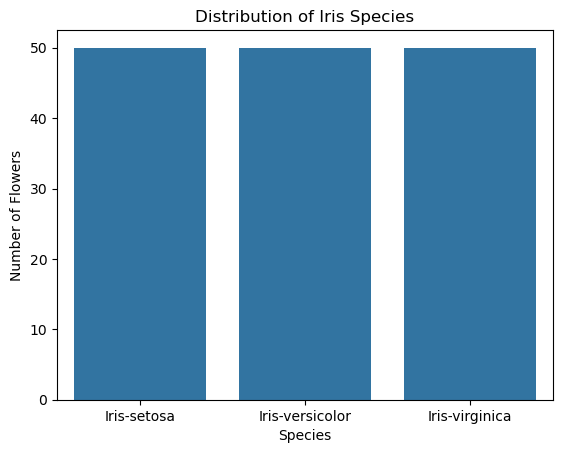

In [22]:
sns.countplot(data=df, x="species")

plt.title("Distribution of Iris Species")
plt.xlabel("Species")
plt.ylabel("Number of Flowers")
plt.show()

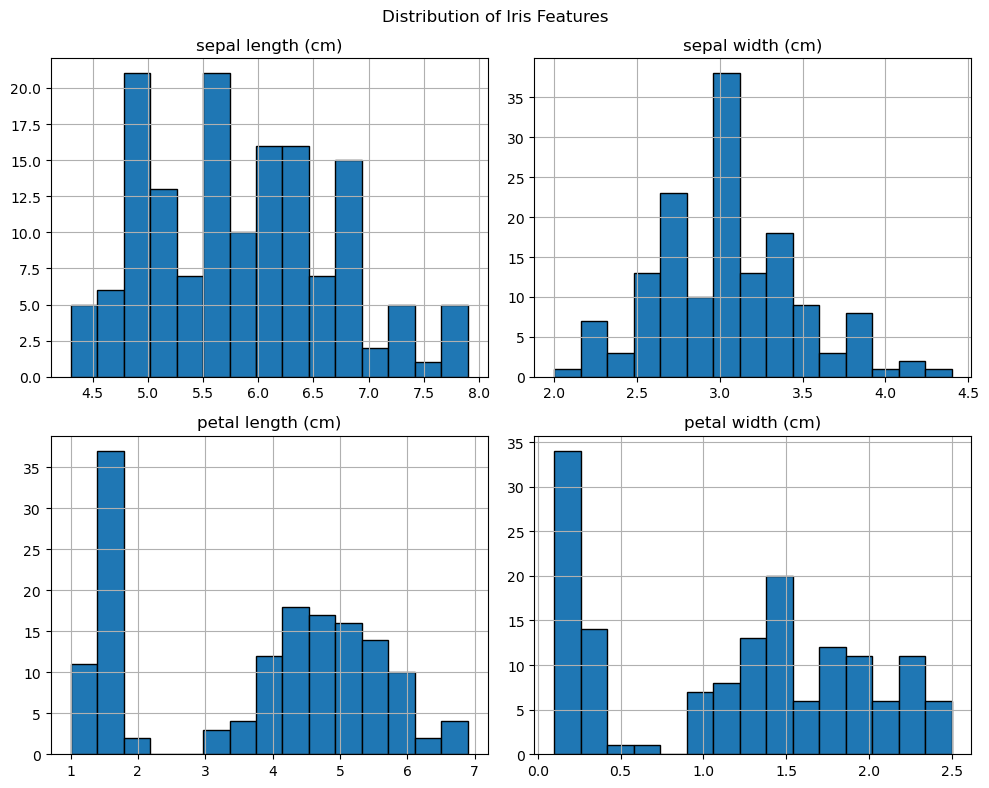

In [23]:

df[iris.feature_names].hist(
    figsize=(10, 8),
    bins=15,
    edgecolor="black"
)

plt.suptitle("Distribution of Iris Features")
plt.tight_layout()
plt.show()

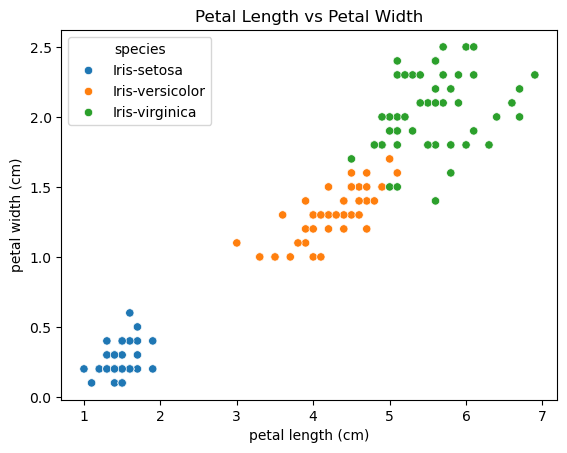

In [24]:

sns.scatterplot(
    data=df,
    x="petal length (cm)",
    y="petal width (cm)",
    hue="species"
)

plt.title("Petal Length vs Petal Width")
plt.show()

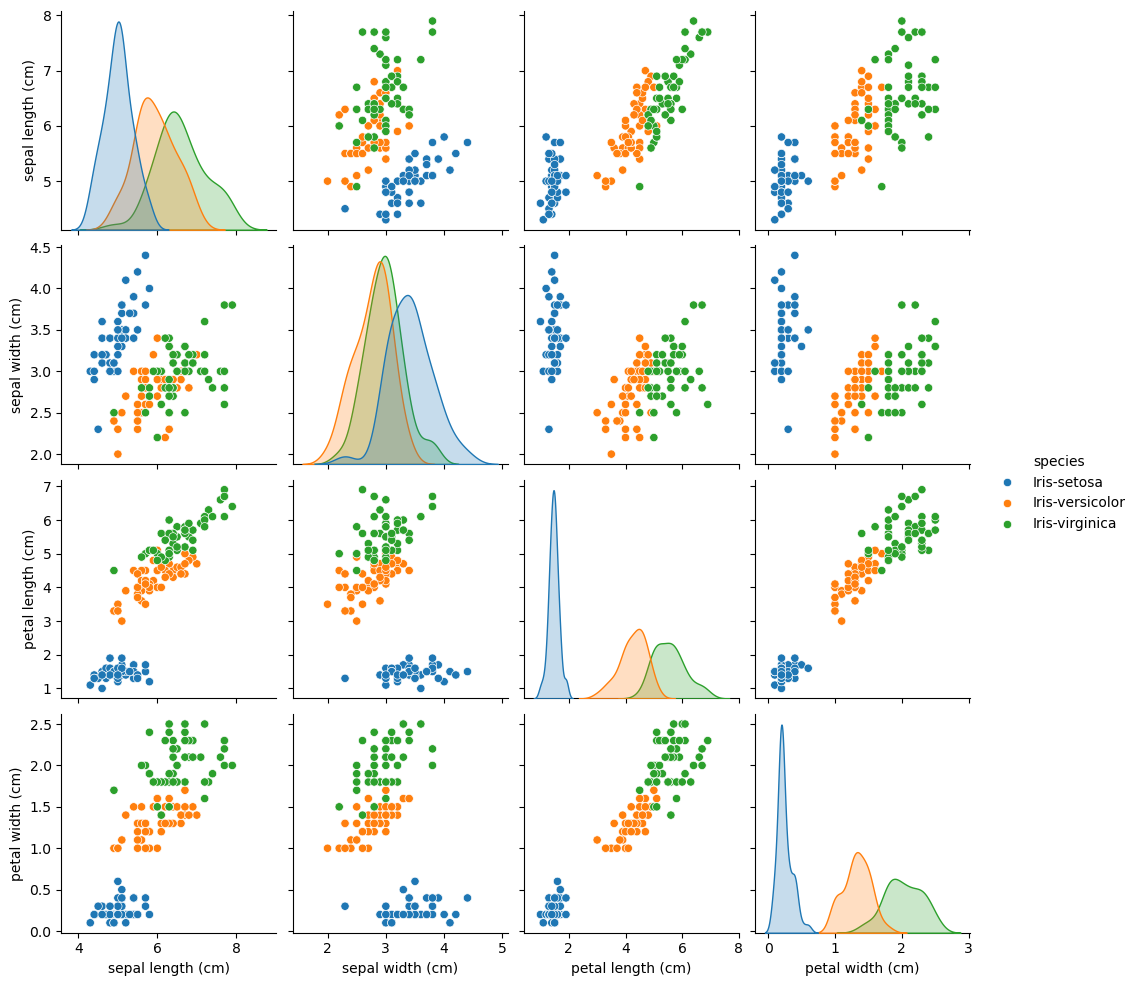

In [26]:

sns.pairplot(
    df,
    vars=iris.feature_names,
    hue="species"
)

plt.show()

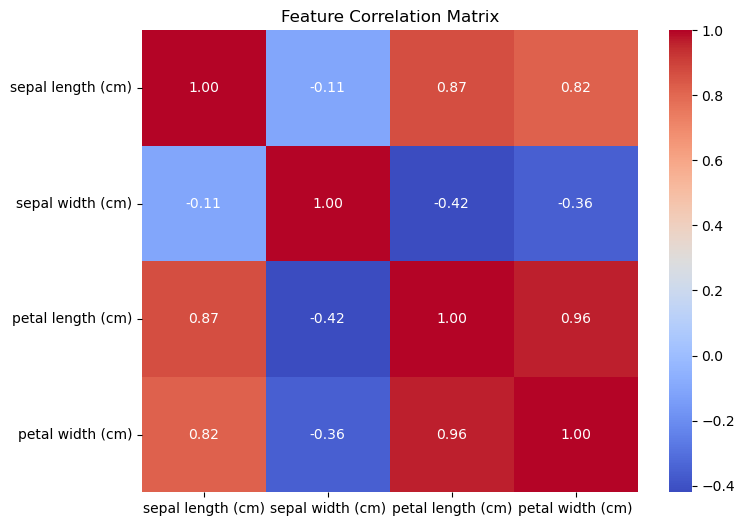

In [27]:

correlation = df[iris.feature_names].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Feature Correlation Matrix")
plt.show()

In [28]:

X = df[iris.feature_names]
y = df["target"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

Feature shape: (150, 4)
Target shape: (150,)


In [29]:

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 120
Testing samples: 30


In [30]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

print("Machine learning algorithms imported successfully!")

Machine learning algorithms imported successfully!


In [31]:

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=500)
    ),

    "K-Nearest Neighbors": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=5)
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    )
}

print("Models created successfully!")

Models created successfully!


In [32]:

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "trained successfully!")

Logistic Regression trained successfully!
K-Nearest Neighbors trained successfully!
Decision Tree trained successfully!
Random Forest trained successfully!


In [33]:

predictions = {}

for name, model in models.items():
    predictions[name] = model.predict(X_test)

print("Predictions generated successfully!")

Predictions generated successfully!


In [34]:

from sklearn.metrics import accuracy_score

results = []

for name, model in models.items():
    y_pred = predictions[name]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred)
    })

results_df = pd.DataFrame(results)
results_df = results_df.sort_values(
    by="Accuracy",
    ascending=False
)

results_df

,Model,Accuracy
0,Logistic Regression,0.933333
1,K-Nearest Neighbors,0.933333
2,Decision Tree,0.933333
3,Random Forest,0.900000


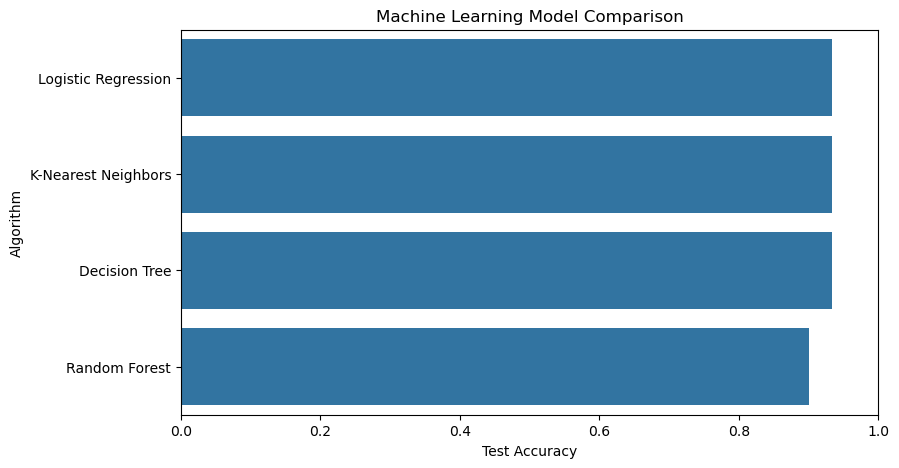

In [35]:

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Accuracy",
    y="Model"
)

plt.title("Machine Learning Model Comparison")
plt.xlim(0, 1)
plt.xlabel("Test Accuracy")
plt.ylabel("Algorithm")
plt.show()

In [36]:

best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

best_predictions = predictions[best_model_name]

print("Best model:", best_model_name)
print(
    "Best test accuracy:",
    round(results_df.iloc[0]["Accuracy"] * 100, 2),
    "%"
)

Best model: Logistic Regression
Best test accuracy: 93.33 %


In [37]:

from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=iris.target_names
    )
)

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



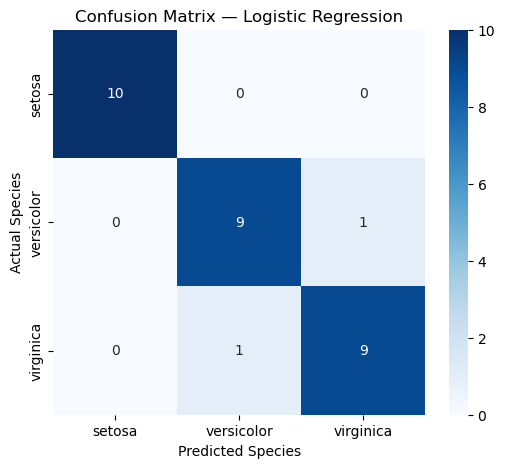

In [38]:

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=iris.target_names,
    yticklabels=iris.target_names
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title(f"Confusion Matrix — {best_model_name}")
plt.show()

In [39]:

new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

new_flower

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2


In [40]:

prediction = best_model.predict(new_flower)[0]

predicted_species = iris.target_names[prediction]

print("Predicted flower species:", predicted_species)

Predicted flower species: setosa


In [41]:

if hasattr(best_model, "predict_proba"):
    probabilities = best_model.predict_proba(new_flower)[0]

    probability_df = pd.DataFrame({
        "Species": iris.target_names,
        "Probability": probabilities
    })

    probability_df["Probability (%)"] = (
        probability_df["Probability"] * 100
    ).round(2)

    display(probability_df)

,Species,Probability,Probability (%)
0,setosa,9.813050e-01,98.13
1,versicolor,1.869474e-02,1.87
2,virginica,2.650772e-07,0.00


In [42]:

import joblib
from pathlib import Path

model_dir = Path("models")
model_dir.mkdir(exist_ok=True)

model_path = model_dir / "iris_model.pkl"

joblib.dump(best_model, model_path)

print("Model saved successfully!")
print("Location:", model_path.resolve())

Model saved successfully!
Location: C:\Users\Devanand\models\iris_model.pkl


In [43]:

loaded_model = joblib.load(model_path)

loaded_prediction = loaded_model.predict(new_flower)[0]

print(
    "Prediction using saved model:",
    iris.target_names[loaded_prediction]
)

Prediction using saved model: setosa



## Conclusion

In this project, an Iris Flower Classification system was developed using supervised machine learning.

The Iris dataset was explored, analyzed, and visualized. Four classification algorithms were trained and compared using test accuracy. The selected model was evaluated using a classification report and confusion matrix.

Finally, the model was used to predict the species of a new flower and was saved for future use.

**Project workflow:** Data Collection → Data Analysis → Preprocessing → Model Training → Evaluation → Prediction → Model Saving.

In [45]:
import joblib
from pprint import pprint

model = joblib.load("models/iris_model.pkl")

print("=" * 60)
print("COMPLETE MODEL")
print("=" * 60)
print(model)

# Get individual components
scaler = model.named_steps["standardscaler"]
classifier = model.named_steps["logisticregression"]

print("\n" + "=" * 60)
print("STANDARD SCALER")
print("=" * 60)
pprint(vars(scaler))

print("\n" + "=" * 60)
print("LOGISTIC REGRESSION")
print("=" * 60)
pprint(vars(classifier))

COMPLETE MODEL
Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=500))])

STANDARD SCALER
{'copy': True,
 'feature_names_in_': array(['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)',
       'petal width (cm)'], dtype=object),
 'mean_': array([5.84166667, 3.04416667, 3.77083333, 1.20416667]),
 'n_features_in_': 4,
 'n_samples_seen_': np.int64(120),
 'scale_': array([0.837415  , 0.44380849, 1.76003768, 0.76063524]),
 'var_': array([0.70126389, 0.19696597, 3.09773264, 0.57856597]),
 'with_mean': True,
 'with_std': True}

LOGISTIC REGRESSION
{'C': 1.0,
 'class_weight': None,
 'classes_': array([0, 1, 2]),
 'coef_': array([[-1.09178245,  1.02034187, -1.79761742, -1.69524109],
       [ 0.53889265, -0.35953943, -0.20791137, -0.8006622 ],
       [ 0.55288981, -0.66080244,  2.0055288 ,  2.49590329]]),
 'dual': False,
 'fit_intercept': True,
 'intercept_': array([-0.31272511,  1.910515  , -1.5977899 ]),
 'interce